# A · Descriptive baseline — how does each floor normally behave?

Floor areas are unknown, so absolute kWh cannot be compared between floors. These KPIs are **ratios and shapes**
that can: how much load is left on overnight, how much AC runs outside the measured schedule, and how often
occupied zones are overcooled. Everything is computed from `data/cleaned/` on usable hours only (`ok`).

| KPI | Definition |
|---|---|
| kWh/day | mean daily total on usable days |
| AC share | AC / (AC + lighting + plug) |
| baseload ratio | mean workday 01:00–04:59 load ÷ mean occupied-hour load |
| after-hours AC share | AC energy outside the floor's measured schedule (incl. weekends, holidays) ÷ all AC energy |
| load factor | mean hourly load ÷ peak hourly load |
| overcooled share | occupied, cooled, sensor-valid hours below 23 °C (AC-energy weighted across zones) |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
from sbanalytics import baseline as B, kpis as K, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
OFFICE = [2, 3, 4, 5, 6, 7]     # F1 has no AC schedule (eda/00 §5): excluded from schedule-based measures

In [3]:
kpi = K.floor_kpis(fh, fd)
comfort = K.zone_comfort(h)
w = comfort.assign(wt=comfort.ac_kwh_in_window)
kpi["overcooled_share"] = (w.share_below_lo * w.wt).groupby(w.floor).sum() / w.wt.groupby(w.floor).sum()
kpi.loc[1, ["baseload_ratio", "after_hours_share", "after_hours_ac_share"]] = np.nan   # no schedule on F1
kpi.to_csv(C.DATA_DERIVED / "floor_kpis.csv")
kpi.round(3)

,ok_days,kwh_per_day,workday_kwh_per_day,nonworkday_kwh_per_day,ac_share,light_share,plug_share,baseload_ratio,after_hours_share,after_hours_ac_share,peak_kw,load_factor,overcooled_share
floor,,,,,,,,,,,,,
1,546,2548.70,2552.54,2538.38,0.31,0.52,0.17,NaN,NaN,NaN,287.35,0.37,NaN
2,527,681.34,918.35,220.58,0.78,0.16,0.06,8.50e-02,0.29,2.82e-01,108.07,0.26,0.80
3,475,520.91,768.28,47.41,0.65,0.28,0.07,9.00e-03,0.18,4.80e-02,137.72,0.16,0.80
4,520,507.12,736.17,67.03,0.68,0.21,0.10,1.40e-02,0.18,4.80e-02,132.11,0.16,0.82
5,520,519.75,761.47,51.33,0.66,0.26,0.08,1.20e-02,0.14,7.00e-03,133.36,0.16,0.68
6,477,519.70,743.14,77.00,0.59,0.33,0.08,1.20e-02,0.22,5.70e-02,124.57,0.17,0.75
7,527,709.92,995.94,153.87,0.78,0.19,0.02,6.00e-03,0.20,1.23e-01,137.15,0.22,0.83


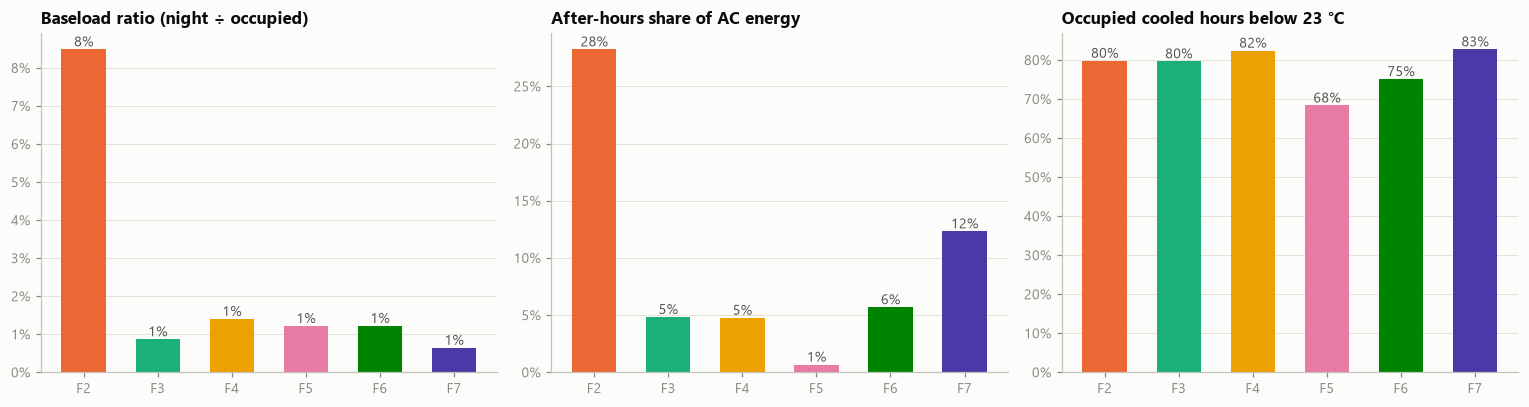

In [4]:
show = {"baseload_ratio": "Baseload ratio (night ÷ occupied)", "after_hours_ac_share": "After-hours share of AC energy",
        "overcooled_share": "Occupied cooled hours below 23 °C"}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (col, title) in zip(axes, show.items()):
    s = kpi.loc[OFFICE, col]
    ax.bar([f"F{f}" for f in s.index], s, color=[viz.FLOOR_COLORS[f] for f in s.index], width=0.6)
    for i, v in enumerate(s):
        ax.text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=viz.INK_2)
    ax.set_title(title, fontsize=11); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}"); ax.grid(axis="x", visible=False)
fig.tight_layout()

In [5]:
for f in OFFICE:
    r = kpi.loc[f]
    print(f"F{f}: {r.kwh_per_day:,.0f} kWh/day, AC {r.ac_share:.0%}, night load {r.baseload_ratio:.0%} of occupied, "
          f"{r.after_hours_ac_share:.0%} of AC outside schedule, {r.overcooled_share:.0%} of occupied cooled hours < 23 °C")

F2: 681 kWh/day, AC 78%, night load 8% of occupied, 28% of AC outside schedule, 80% of occupied cooled hours < 23 °C
F3: 521 kWh/day, AC 65%, night load 1% of occupied, 5% of AC outside schedule, 80% of occupied cooled hours < 23 °C
F4: 507 kWh/day, AC 68%, night load 1% of occupied, 5% of AC outside schedule, 82% of occupied cooled hours < 23 °C
F5: 520 kWh/day, AC 66%, night load 1% of occupied, 1% of AC outside schedule, 68% of occupied cooled hours < 23 °C
F6: 520 kWh/day, AC 59%, night load 1% of occupied, 6% of AC outside schedule, 75% of occupied cooled hours < 23 °C
F7: 710 kWh/day, AC 78%, night load 1% of occupied, 12% of AC outside schedule, 83% of occupied cooled hours < 23 °C


## Day types the calendar misses — clustering daily load shapes

Each floor-day's 24-hour profile, divided by its own mean (so the *shape* is clustered, not the size). k-means, k chosen by silhouette score. Office floors only.

silhouette by k: {2: 0.51, 3: 0.494, 4: 0.507, 5: 0.504, 6: 0.498} -> k = 2


day_type,closure,holiday,holiday_worked,weekend,workday
cluster,,,,,
0,1,24,6,214,1941
1,10,173,0,592,37


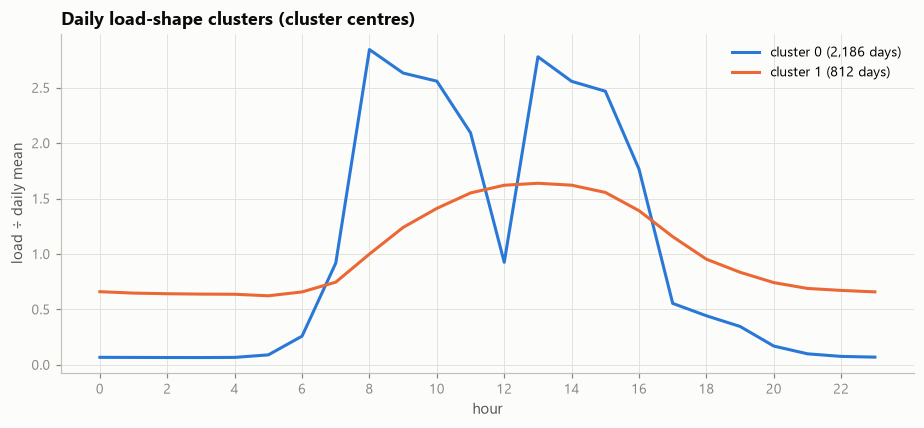

In [6]:
prof = K.daily_profiles(fh[fh.floor.isin(OFFICE)])
labels, centres, sil = K.cluster_profiles(prof)
print("silhouette by k:", sil.round(3).to_dict(), "-> k =", centres.shape[0])

fig, ax = plt.subplots(figsize=(10, 4))
sizes = labels.cluster.value_counts()
for c in centres.index:
    ax.plot(range(24), centres.loc[c], color=viz.CATEGORICAL[c], label=f"cluster {c} ({sizes[c]:,} days)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour"); ax.set_ylabel("load ÷ daily mean")
ax.set_title("Daily load-shape clusters (cluster centres)"); ax.legend()
pd.crosstab(labels.cluster, labels.day_type)

In [7]:
# The cluster whose centre has the highest 08-16 h share is the "operating day" shape.
operating = int(centres.loc[:, 8:16].mean(axis=1).idxmax())
odd = labels[(labels.cluster == operating) & labels.day_type.isin(["weekend", "holiday", "closure"])].reset_index()
odd["weekday"] = odd.day.dt.day_name()
print(f"{len(odd)} weekend/holiday floor-days have a full operating-day shape:")
odd.groupby("floor").size().rename("days").to_frame().T

239 weekend/holiday floor-days have a full operating-day shape:


floor,2,3,4,5,6,7
days,26,59,30,24,24,76


These non-working days that *look like* working days are where after-hours cooling comes from. They feed the
anomaly register (D) and the schedule recommendation (F). A day shape alone does not say whether the run was
authorised (an exam, an event) — that is the question to put to facilities management.